# Circular-grid Bayesian phase estimation

This original bounded example uses explicit fresh-preparation Hadamard circuits and a posterior-only adaptive experiment rule. Saved numerical results are finite-grid, ideal-model evidence. The credible cell arc is not a confidence guarantee for continuous phases or hardware.

In [1]:
from pathlib import Path
import hashlib, importlib.util, json, os, stat, sys
from IPython.display import Markdown, SVG, display

def read_regular(path, cap):
    fd = os.open(path, os.O_RDONLY | os.O_NOFOLLOW | os.O_NONBLOCK)
    try:
        before = os.fstat(fd)
        assert stat.S_ISREG(before.st_mode) and 0 <= before.st_size <= cap
        with os.fdopen(fd, 'rb', closefd=False) as handle:
            raw = handle.read(cap + 1)
        after = os.fstat(fd)
        named = os.stat(path, follow_symlinks=False)
        identity = lambda info: (info.st_dev, info.st_ino, info.st_size, info.st_mtime_ns, info.st_ctime_ns)
        assert len(raw) == before.st_size and identity(before) == identity(after) == identity(named)
        return raw
    finally:
        os.close(fd)

choices = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in choices if (p / 'src/openquantum/bayesian_qpe.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Extract the complete code package and open this notebook from its root or notebooks directory.')
records = Path(os.environ.get('OPENQUANTUM_BAYESIAN_RECORDS', str(ROOT / 'assets/generated/bayesian-qpe')))
manifest = json.loads(read_regular(records / 'manifest.json', 256 * 1024))
assert manifest['schema'] == 'openquantum-bayesian-qpe-files-v1'
assert isinstance(manifest['files'], dict) and len(manifest['files']) <= 512
assert all(type(v['bytes']) is int and 0 <= v['bytes'] <= 16 * 1024 * 1024 for v in manifest['files'].values())
assert type(manifest['payload_bytes']) is int and manifest['payload_bytes'] == sum(v['bytes'] for v in manifest['files'].values()) <= 16 * 1024 * 1024
def read_payload(name):
    assert isinstance(name, str) and Path(name).name == name and name not in ('.', '..')
    expected = manifest['files'][name]
    assert isinstance(expected['sha256'], str) and len(expected['sha256']) == 64 and all(c in '0123456789abcdef' for c in expected['sha256'])
    raw = read_regular(records / name, expected['bytes'])
    assert len(raw) == expected['bytes'] and hashlib.sha256(raw).hexdigest() == expected['sha256']
    return raw
for name in manifest['files']:
    read_payload(name)
source = ROOT / 'src/openquantum/bayesian_qpe.py'
source_bytes = read_regular(source, 1024 * 1024)
assert hashlib.sha256(source_bytes).hexdigest() == manifest['source_sha256']['bayesian_qpe.py']
assert source_bytes == read_payload('bayesian_qpe.py')
spec = importlib.util.spec_from_file_location('openquantum_bayesian_notebook_source', source)
bq = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = bq
exec(compile(source_bytes, str(source), 'exec'), bq.__dict__)
study = json.loads(read_payload('results.json'))
assert study['status'] == 'checked_prescribed_ideal_grid_bayes_study'
print('Checked scientific payload hashes; no QPU or physical estimator is involved.')

Checked scientific payload hashes; no QPU or physical estimator is involved.


(bayesian-qpe-circuit)=
## Two literal controlled calls

The diagram contains resets, the supplied target preparation, every controlled base call, the selected measurement phase and readout. Its source and lowered operators were checked independently by the producer.

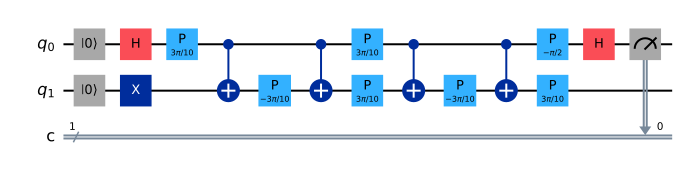

In [2]:
display(SVG(data=read_payload('circuit.svg').decode()))

(bayesian-qpe-summary)=
## Prescribed transcripts

All observations are charged. Error values below are retained empirical results, and the reported 95% posterior mass is a discrete model summary.

In [3]:
rows = ['| Nominal phase | Root seed | Estimate | Circular error | Cell-arc width | Base calls | Fresh trials |',
        '|---:|---:|---:|---:|---:|---:|---:|']
for record in study['records']:
    ledger = record['ledger']
    rows.append(f"| {record['nominal_phase']:.6g} | {record['root_seed']} | {record['estimate']:.8g} | {record['circular_error']:.5g} | {record['summary']['credible_arc']['width']:.5g} | {ledger['shot_weighted_controlled_U_calls']} | {ledger['complete_fresh_preparations']} |")
display(Markdown('\n'.join(rows)))
print('Represented fresh trials:', study['total_modeled_fresh_trials'])
print('Literal controlled base calls:', study['total_literal_controlled_U_calls'])
print('Uniform confidence certificate:', study['uniform_confidence_certificate'])

| Nominal phase | Root seed | Estimate | Circular error | Cell-arc width | Base calls | Fresh trials |
|---:|---:|---:|---:|---:|---:|---:|
| 0.3 | 7 | 0.29902959 | 0.00097041 | 0.0039062 | 1168 | 48 |
| 0.3 | 19 | 0.30002327 | 2.3275e-05 | 0.0058594 | 1278 | 48 |
| 0.995 | 7 | 0.99427302 | 0.00072698 | 0.0039062 | 1323 | 48 |
| 0.995 | 19 | 0.99462545 | 0.00037455 | 0.0039062 | 1323 | 48 |
| 0.125 | 7 | 0.12494043 | 5.9573e-05 | 0.0039062 | 1329 | 48 |
| 0.125 | 19 | 0.12483306 | 0.00016694 | 0.0039062 | 1267 | 48 |
| 0.5 | 7 | 0.50091166 | 0.00091166 | 0.0039062 | 1367 | 48 |
| 0.5 | 19 | 0.5 | 0 | 0.0058594 | 1391 | 48 |

Represented fresh trials: 384
Literal controlled base calls: 10446
Uniform confidence certificate: False


(bayesian-qpe-posterior)=
## Posterior and observed entropy

Individual observations may increase entropy. The greedy rule optimizes a finite-grid expected entropy calculation over the specified candidates, with numerical tie handling; it does not establish optimal quantum resource use.

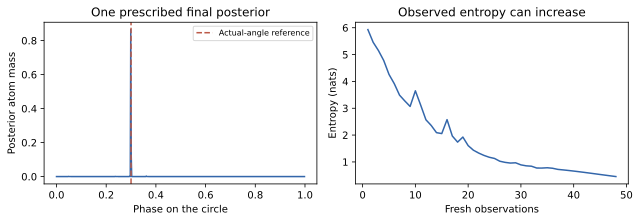

Grid spacing: 0.001953125
Classical policy calls including preflight: 49
Credible cell-arc scope: discrete posterior grid-cell arc, not continuous or frequentist coverage; not a disjoint HPD set
Physical estimate performed: False


In [4]:
display(SVG(data=read_payload('posterior.svg').decode()))
record = study['records'][0]
print('Grid spacing:', record['summary']['grid_spacing'])
print('Classical policy calls including preflight:', record['ledger']['classical_policy_calls'])
print('Credible cell-arc scope:', record['summary']['credible_scope'])
print('Physical estimate performed:', record['ledger']['physical_estimate_performed'])

## Optional bounded live experiment

Static publication keeps these controls disabled. In a trusted live kernel, set `OPENQUANTUM_STATIC_BUILD=0` and rerun the cell to try a 12-observation one-target example. New outcomes have the same model limitations and no uniform success claim.

In [5]:
if os.environ.get('OPENQUANTUM_STATIC_BUILD', '1') == '1':
    print('Static mode: bounded live controls are disabled.')
else:
    import ipywidgets as widgets
    phase = widgets.FloatSlider(value=.3, min=.001, max=.999, step=.001, description='Phase')
    button = widgets.Button(description='Run 12 fresh observations')
    output = widgets.Output()
    def run_clicked(_):
        with output:
            output.clear_output(wait=True)
            result = bq.run_adaptive(float(phase.value), target_qubits=1, steps=12, grid_size=128, seed=7)
            print({key: result[key] for key in ('estimate', 'circular_error', 'uniform_confidence_certificate')})
            print('95% discrete posterior cell arc:', result['summary']['credible_arc'])
    button.on_click(run_clicked)
    display(phase, button, output)

Static mode: bounded live controls are disabled.
